# Численное дифференцирование и интегрирование / 数值微分与积分

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#356AE6", "#E07A25", "#2B8A6E", "#A64B78"]),
})
from scipy.integrate import simpson
from scipy.optimize import root_scalar

## 1. Производная $\sin x$ / $\sin x$ 的导数
В точке $x=1$ сравним прямую и центральную разности с точной производной $\cos x$. Углы задаются в радианах.

在 $x=1$ 处，比较前向差分、中心差分与精确导数 $\cos x$。角度使用弧度。

In [2]:
f = np.sin
x = 1.0
h = 1e-3
df_forward = (f(x + h) - f(x)) / h
df_central = (f(x + h) - f(x - h)) / (2*h)
df_exact = np.cos(x)
err_forward = abs(df_forward - df_exact)
err_central = abs(df_central - df_exact)
print("Forward:", df_forward, "error:", err_forward)
print("Central:", df_central, "error:", err_central)
print("Exact:  ", df_exact)

Forward: 0.5398814803603269 error: 0.0004208255078128609
Central: 0.5403022158177451 error: 9.00503946965614e-08
Exact:   0.5403023058681398


## 2. Выбор шага / 步长选择
При достаточно большом $h$ преобладает ошибка аппроксимации: $O(h)$ для прямой и $O(h^2)$ для центральной разности. При очень малом $h$ вычитание близких чисел усиливает влияние округления.

步长较大时，前向差分和中心差分的截断误差分别为 $O(h)$ 和 $O(h^2)$。步长过小时，相近数相减会放大舍入误差的影响。

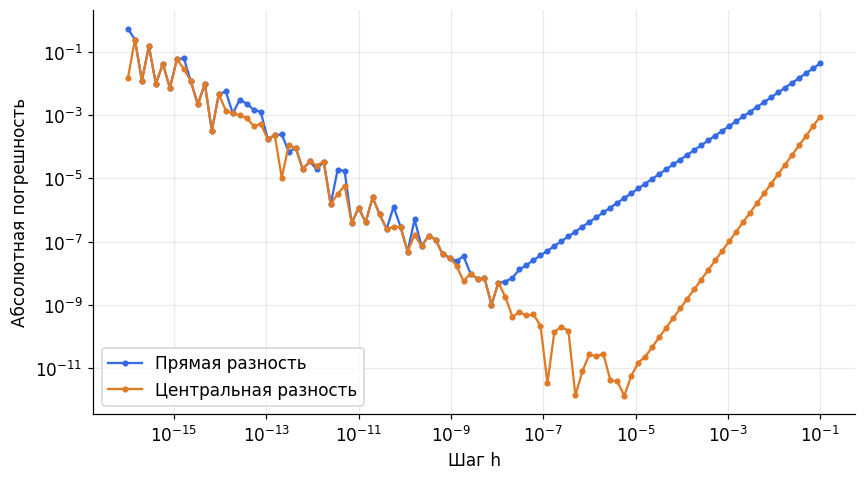

Лучший h в этой выборке / 本次采样中的最优步长:
Forward: 7.56463327554629e-09
Central: 5.72236765935022e-06


In [3]:
h_values = np.logspace(-16, -1, 100)
forward_values = (np.sin(x + h_values) - np.sin(x)) / h_values
central_values = (np.sin(x + h_values) - np.sin(x - h_values)) / (2*h_values)
forward_errors = np.abs(forward_values - np.cos(x))
central_errors = np.abs(central_values - np.cos(x))
fig, ax = plt.subplots()
for errors, label in [(forward_errors, "Прямая разность"), (central_errors, "Центральная разность")]:
    positive = errors > 0
    ax.loglog(h_values[positive], errors[positive], ".-", label=label)
ax.set(xlabel="Шаг h", ylabel="Абсолютная погрешность")
ax.legend()
fig.tight_layout()
plt.show()
print("Лучший h в этой выборке / 本次采样中的最优步长:")
print("Forward:", h_values[np.argmin(forward_errors)])
print("Central:", h_values[np.argmin(central_errors)])

Минимум ошибки относится к этой функции, точке и набору шагов. Нулевые ошибки, если они возникают при округлении, пропущены на логарифмической оси.

这里的最小误差只对应当前函数、计算点和采样步长。若舍入后误差恰好为零，则在对数坐标图中跳过该点。

## 3. Интеграл $\sin x$ / $\sin x$ 的积分
$$\int_0^\pi\sin x\,dx=2.$$
Используем 100 равных интервалов, то есть 101 узел. Для составной формулы Симпсона на равномерной сетке число интервалов выбираем чётным.

使用 100 个等长子区间，即 101 个节点。等距网格上的标准复合 Simpson 公式需要偶数个子区间。

In [4]:
N = 100
x_int = np.linspace(0, np.pi, N + 1)
y_int = np.sin(x_int)
I_trap = np.trapezoid(y_int, x_int)
I_simp = simpson(y_int, x=x_int)
I_exact = 2.0
print("Trapezoid:", I_trap)
print("Simpson:  ", I_simp)
print("Error trap:", abs(I_trap - I_exact))
print("Error simp:", abs(I_simp - I_exact))

Trapezoid: 1.9998355038874434
Simpson:   2.0000000108245044
Error trap: 0.00016449611255664465
Error simp: 1.0824504403927904e-08


## 4. Откуда берётся приближение площади / 面积近似的来源
На грубой сетке видны различия: метод трапеций соединяет узлы отрезками, метод Симпсона использует параболу на каждой паре интервалов.

在粗网格上可以看出区别：梯形法以线段连接节点，Simpson 法在每两个子区间上用一条抛物线近似。

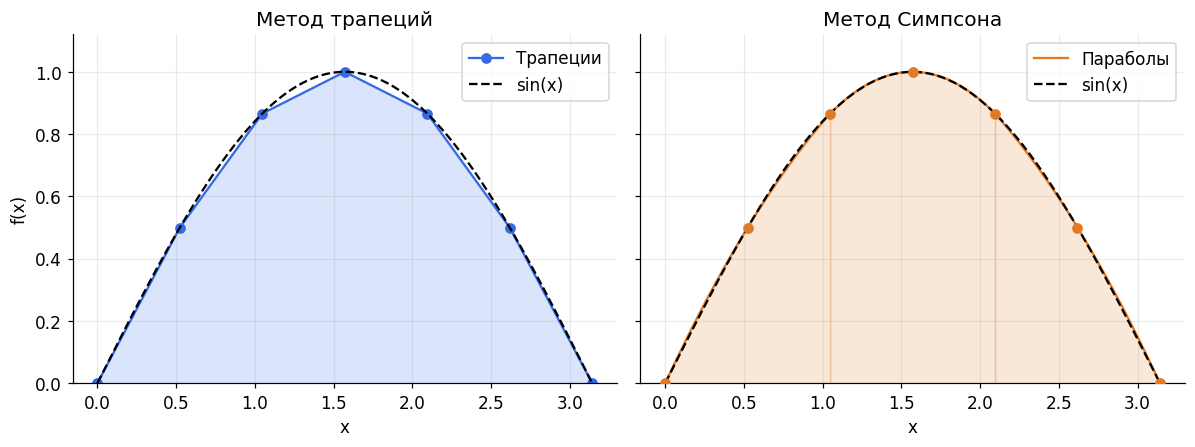

In [5]:
x_nodes = np.linspace(0, np.pi, 7)
y_nodes = np.sin(x_nodes)
x_dense = np.linspace(0, np.pi, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
axes[0].plot(x_nodes, y_nodes, "o-", label="Трапеции")
axes[0].fill_between(x_nodes, y_nodes, alpha=0.18)
for i in range(0, 6, 2):
    x_local = x_nodes[i:i+3]
    coefficients = np.polyfit(x_local, y_nodes[i:i+3], 2)
    x_piece = np.linspace(x_local[0], x_local[-1], 80)
    y_piece = np.polyval(coefficients, x_piece)
    axes[1].plot(x_piece, y_piece, color="#E07A25", label="Параболы" if i == 0 else None)
    axes[1].fill_between(x_piece, y_piece, color="#E07A25", alpha=0.18)
axes[1].scatter(x_nodes, y_nodes, color="#E07A25", zorder=3)
for ax, title in zip(axes, ["Метод трапеций", "Метод Симпсона"]):
    ax.plot(x_dense, np.sin(x_dense), "k--", label="sin(x)")
    ax.set(xlabel="x", title=title, ylim=(0, 1.12))
    ax.legend()
axes[0].set_ylabel("f(x)")
fig.tight_layout()
plt.show()

## 5. Сходимость при сгущении сетки / 加密网格时的收敛
Удваиваем число интервалов и сравниваем абсолютные ошибки. Для этой гладкой функции ожидаем второй порядок у трапеций и четвёртый у Симпсона.

依次将子区间数加倍，比较绝对误差。对本例的光滑函数，梯形法预期为二阶，Simpson 法为四阶。

In [6]:
interval_counts = np.array([10, 20, 40, 80, 160, 320])
trap_errors, simpson_errors = [], []
for n in interval_counts:
    grid = np.linspace(0, np.pi, n + 1)
    values = np.sin(grid)
    trap_errors.append(abs(np.trapezoid(values, grid) - 2))
    simpson_errors.append(abs(simpson(values, x=grid) - 2))
trap_errors = np.array(trap_errors)
simpson_errors = np.array(simpson_errors)
print(f"{'N':>5} {'Error trap':>14} {'Error Simpson':>16}")
for n, et, es in zip(interval_counts, trap_errors, simpson_errors):
    print(f"{n:5d} {et:14.5e} {es:16.5e}")
print("Порядок / 阶数 trap:", np.log2(trap_errors[:-1]/trap_errors[1:]))
print("Порядок / 阶数 Simpson:", np.log2(simpson_errors[:-1]/simpson_errors[1:]))

    N     Error trap    Error Simpson
   10    1.64765e-02      1.09517e-04
   20    4.11403e-03      6.78444e-06
   40    1.02819e-03      4.23093e-07
   80    2.57028e-04      2.64288e-08
  160    6.42556e-05      1.65157e-09
  320    1.60638e-05      1.03220e-10
Порядок / 阶数 trap: [2.00178326 2.00044518 2.00011125 2.00002781 2.00000695]
Порядок / 阶数 Simpson: [4.01278505 4.00318278 4.00079487 4.00019865 4.00004849]


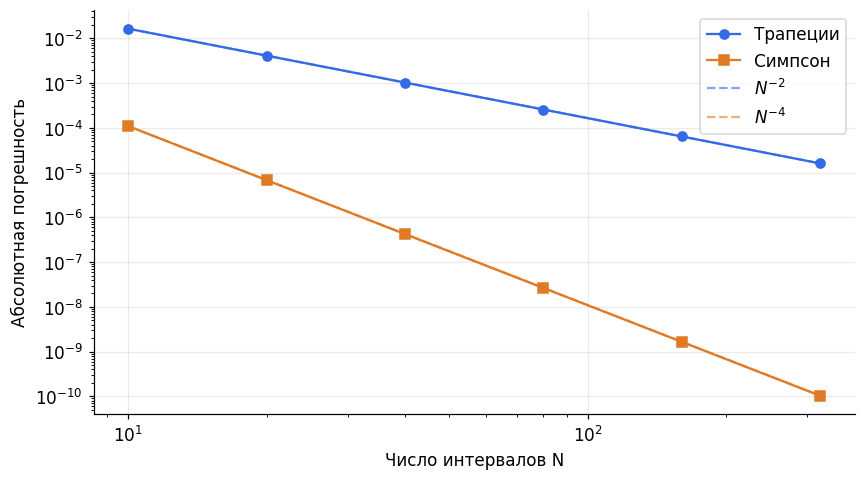

In [7]:
fig, ax = plt.subplots()
ax.loglog(interval_counts, trap_errors, "o-", label="Трапеции")
ax.loglog(interval_counts, simpson_errors, "s-", label="Симпсон")
ax.loglog(interval_counts, trap_errors[0]*(interval_counts[0]/interval_counts)**2,
          "--", color="#356AE6", alpha=0.6, label=r"$N^{-2}$")
ax.loglog(interval_counts, simpson_errors[0]*(interval_counts[0]/interval_counts)**4,
          "--", color="#E07A25", alpha=0.6, label=r"$N^{-4}$")
ax.set(xlabel="Число интервалов N", ylabel="Абсолютная погрешность")
ax.legend()
fig.tight_layout()
plt.show()

## 6. Температурный градиент и закон Фурье / 温度梯度与傅里叶定律
Используем температурные данные: $x$ в метрах, $T$ в K. Примем постоянную теплопроводность $\lambda=10$ W/(m·K) и вычислим плотность теплового потока $q_x=-\lambda\,dT/dx$ в W/m².
`np.gradient(..., edge_order=2)` использует центральные разности внутри сетки и односторонние формулы второго порядка на границах.

使用温度数据，位置单位为 m，温度单位为 K。假设导热系数恒定为 $\lambda=10$ W/(m·K)，由 $q_x=-\lambda\,dT/dx$ 计算热流密度，单位 W/m²。
`np.gradient(..., edge_order=2)` 在内部节点使用中心差分，在两端使用二阶单边差分。

In [8]:
x_T = np.array([0., 1., 2., 3., 4.])
T = np.array([300., 315., 327., 346., 358.])
conductivity = 10.0
temperature_gradient = np.gradient(T, x_T, edge_order=2)
heat_flux = -conductivity * temperature_gradient
print("x [m], T [K], dT/dx [K/m], q [W/m^2]")
print(np.column_stack((x_T, T, temperature_gradient, heat_flux)))

x [m], T [K], dT/dx [K/m], q [W/m^2]
[[   0.   300.    16.5 -165. ]
 [   1.   315.    13.5 -135. ]
 [   2.   327.    15.5 -155. ]
 [   3.   346.    15.5 -155. ]
 [   4.   358.     8.5  -85. ]]


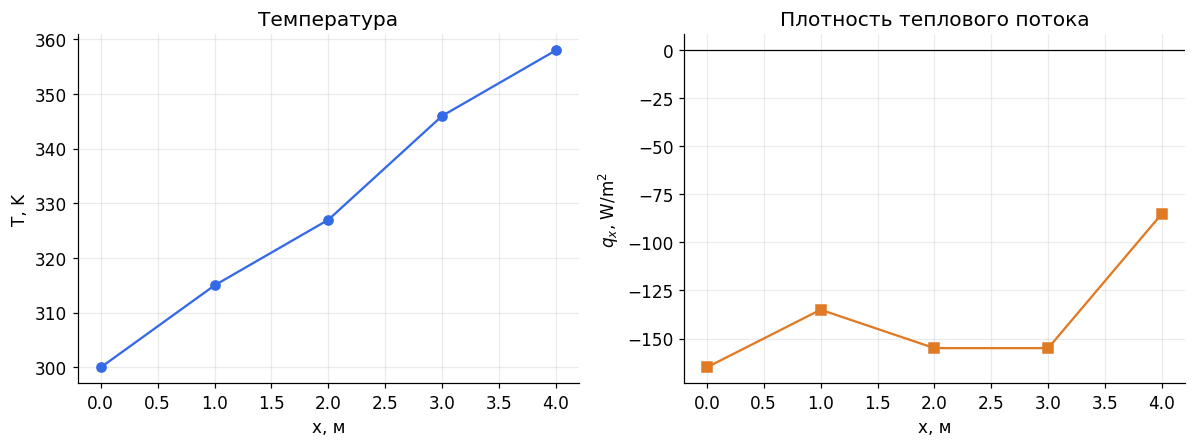

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(x_T, T, "o-")
axes[0].set(xlabel="x, м", ylabel="T, K", title="Температура")
axes[1].plot(x_T, heat_flux, "s-", color="#E07A25")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="x, м", ylabel=r"$q_x$, W/m$^2$", title="Плотность теплового потока")
fig.tight_layout()
plt.show()

Температура растёт с координатой, поэтому поток направлен в сторону уменьшения `x`: значения `q_x` отрицательны. Численное дифференцирование чувствительно к шуму измерений.

温度随位置增大而升高，热流指向 `x` 减小的方向，因此 `q_x` 为负。对测量数据求数值导数时，需要注意噪声的影响。

## 7. Средняя температура / 平均温度
$$\overline{T}=\frac{1}{L}\int_{x_0}^{x_1}T(x)\,dx,\qquad L=x_1-x_0.$$
Для дискретных данных сравним две оценки интеграла. Точный непрерывный профиль неизвестен, поэтому различие результатов не является известной точной ошибкой.

用两种积分方法估计离散温度数据的空间平均值。连续温度分布未知，所以两种结果之差不能直接当作已知的精确误差。

In [10]:
length = x_T[-1] - x_T[0]
mean_trap = np.trapezoid(T, x_T) / length
mean_simpson = simpson(T, x=x_T) / length
print("Средняя температура / 平均温度, K:")
print("Trapezoid:", mean_trap)
print("Simpson:  ", mean_simpson)

Средняя температура / 平均温度, K:
Trapezoid: 329.25
Simpson:   329.66666666666663


## 8. Пример: $g(x)=x^3-x-1$ / 例题：$g(x)=x^3-x-1$
Найдём корень на $[1,2]$, оценим производную в корне и вычислим интеграл на этом интервале. Аналитически $\int_1^2g(x)\,dx=1.25$.

求 $[1,2]$ 内的根，在根处用中心差分估计导数，并计算该区间内的积分。解析积分值为 $1.25$。

In [11]:
g = lambda x: x**3 - x - 1
cubic_root = root_scalar(g, bracket=[1, 2], method="brentq").root
h_cubic = 1e-4
cubic_derivative = (g(cubic_root+h_cubic) - g(cubic_root-h_cubic)) / (2*h_cubic)
cubic_exact_derivative = 3*cubic_root**2 - 1
x_cubic = np.linspace(1, 2, 101)
cubic_trap = np.trapezoid(g(x_cubic), x_cubic)
cubic_simpson = simpson(g(x_cubic), x=x_cubic)
print("Root:", cubic_root)
print("Derivative:", cubic_derivative, "exact:", cubic_exact_derivative)
print("Integral trapezoid:", cubic_trap, "error:", abs(cubic_trap - 1.25))
print("Integral Simpson:  ", cubic_simpson, "error:", abs(cubic_simpson - 1.25))

Root: 1.324717957244746
Derivative: 4.264633008739249 exact: 4.264632998740079
Integral trapezoid: 1.250075 error: 7.500000000004725e-05
Integral Simpson:   1.25 error: 0.0
